## Thêm các thư viện cần thiết

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_excel(r'D:\DOAN\machine_learning\lab05\data\Online_Retail.xlsx')

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
df.shape

(541909, 8)

* nhiều dữ liệu bị mất ở CustomerID

In [11]:
cols=['CustomerID']
def ismissing(cols, df: pd.DataFrame):
    for col in cols:
        missingcount = df[col].isnull().sum()
        totalcount = len(df[col])
        missingper = missingcount / totalcount * 100

        print(f"{col}:")
        print(f"  Missing count: {missingcount}")
        print(f"  Missing percentage: {missingper:.2f}%")

In [12]:
ismissing(cols,df)

CustomerID:
  Missing count: 135080
  Missing percentage: 24.93%


* Cột CustomerID có khoảng 24.93% giá trị bị thiếu. Cần xem xét mối quan hệ giữa cột này và biến mục tiêu (target) cũng như các đặc trưng khác để đánh giá giá trị sử dụng của nó.

* Tuy nhiên, CustomerID chủ yếu là biến định danh, dùng để phân biệt khách hàng, không trực tiếp phản ánh đặc điểm hay hành vi của khách hàng. Vì vậy, nếu không có bằng chứng cho thấy mã khách hàng mang thông tin hữu ích cho mô hình, nên cân nhắc loại bỏ cột này.

* Nếu CustomerID có vai trò quan trọng trong việc liên kết dữ liệu từ nhiều bảng hoặc xác định các giao dịch của cùng một khách hàng, cần giữ lại trong dữ liệu gốc để phục vụ các bước xử lý tiếp theo.

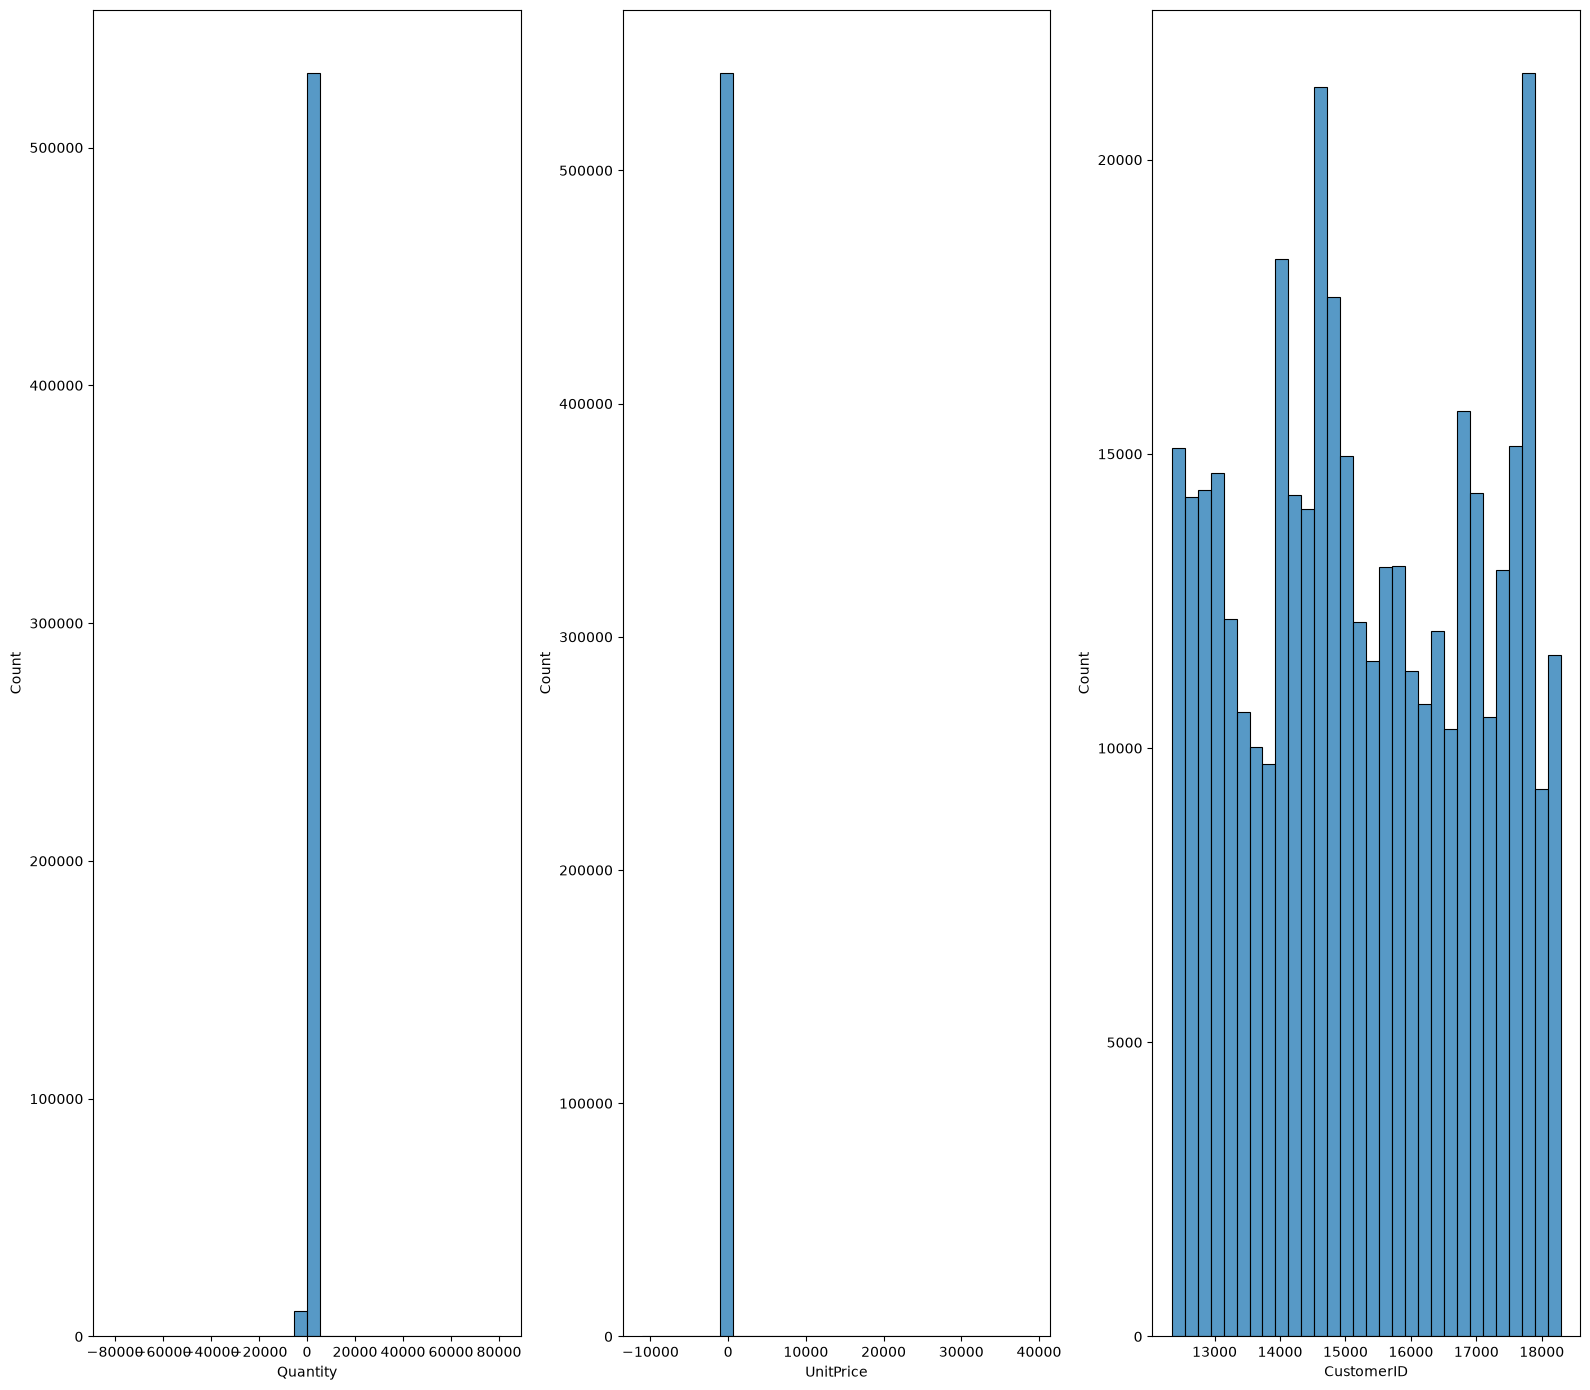

In [ ]:
# cols=df.select_dtypes(include='number').columns.to_list()
# sns.histplot(data=df,x='CustomerID',hue='Country')

cols = ['Quantity', 'UnitPrice']
fig,axes=plt.subplots(1,2,figsize=(16,4*3.5))
for ax,col in zip(axes,cols):
    sns.scatterplot(
        data=df,
        x='CustomerID',
        y=col,
        alpha=0.3,
        s=10,
        ax=ax
    )
    ax.set_title(f'CustomerID vs {col}')

plt.tight_layout()
plt.show()

In [6]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303
